<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/HybridQNN_SecureIoTLocalization_Jabberi2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-CNN for secure IoT localisation under NIFS attacks: Jabberi et al. (2025) step by step

**Paper.** Maher Jabberi, Akram Hakiri, Bassem Sellami, Adel M. Alimi, *Hybrid Quantum-CNN Framework for Secure, Robust, and Efficient IoT Localization under Adversarial Signal Attacks*, 14th IFIP/IEEE International Conference on Performance Evaluation and Modeling in Wired and Wireless Networks (PEMWN), 2025. DOI [10.23919/PEMWN67312.2025.11304017](https://doi.org/10.23919/PEMWN67312.2025.11304017).

**What the paper does.** A mobile IoT node estimates its position from signed time-of-flight distances to static anchors. Some anchors are compromised and mount a **Neutralization-Inspired Fake Signal (NIFS)** attack: they answer a little late, which adds a small, valid-looking bias to the measured distance. The paper proposes a **hybrid quantum-CNN (HQC-NN)**: a small parameterised quantum circuit turns the distance vector into quantum features, a CNN turns those into a position. A **K-Means** stage can route each sample to a cluster-specialised CNN (CNN-KMeans, HQC-NN-KMeans). Every packet carries an **Ed25519** signature. The evaluation (Figs. 1-3) is a simulation of 1000 mobile nodes over 100 iterations, comparing energy, latency and a "detection accuracy factor" (DAF) of four models.

**Where the data come from. Read this first.** The paper uses **no dataset**: it generates its measurements from the model of its Eqs. (1), (2) and (7) (Gaussian random-walk mobility, time-of-flight ranging with Gaussian noise, NIFS delay `delta = c * dt`). No real RSSI/CSI recording is involved, and the paper does not release its simulator. Following the project rule (generate signals only when the paper itself generates its data from a stated model), this notebook **simulates exactly that model**. Every number below therefore comes from simulated, not measured, radio data, and the values the paper leaves open (area, anchor count, noise levels, attack strength) are our choices, listed in the table below.

**What this notebook does.**

1. simulates the paper's mobility, ranging and NIFS model for train / validation / test nodes, and explores the simulated data (class counts, PCA scatter coloured by the true label, trajectories);
2. builds the **HQC-NN** (an 8-qubit PennyLane circuit, drawn from the real QNode) and the three other models of the paper (CNN, CNN-KMeans, HQC-NN-KMeans), plus least-squares multilateration, a Random Forest and an RBF-SVR on identical inputs;
3. trains them on a clean/attacked mix (Eq. 3) and measures the localisation error without attack, under NIFS, and under a stronger unseen NIFS;
4. implements the **Ed25519** packet verification of Algorithm 1 with real signatures and shows what it does (and does not) stop;
5. re-draws the paper's Figs. 1-3 (energy, latency, DAF over iterations) from our own measurements and a documented cost model;
6. adds a white-box FGSM / PGD "worst-case NIFS" attack, the repository's usual robustness test, which the paper only mentions;
7. prints the paper's numbers next to ours with a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. No download and no GPU. `FAST_MODE = True` is a class demo (300 nodes, 30 iterations, one seed); `FAST_MODE = False` is the paper's scale (1000 nodes, 100 iterations, three seeds). The run time is printed at the end.

## The paper in one page

- **Problem.** Estimate the position `x_t` of `M` mobile nodes from ranges `d_i` to `N` static anchors while an unknown subset of anchors is malicious. Minimise `alpha * eps_normal + beta * eps_attack + gamma * (1 - DAF)` (Eq. 3) under latency, energy and update-rate constraints `T_total <= T_max`, `E_total <= E_budget`, `1/T_total >= R_min` (Eqs. 4-6).
- **Mobility (Eq. 1).** `x_k = x_{k-1} + v*dt + omega`, `omega ~ N(0, sigma_w^2 I)`.
- **Ranging (Eq. 2).** `d_i = |x_t - x_i| + eps_i + delta_i^attack`, `eps_i ~ N(0, sigma_i^2)`.
- **NIFS attack (Eq. 7).** A compromised anchor delays its answer by `dt_i`, so `delta_i = c * dt_i`. The attacker keeps `dt_i` small to stay undetected. Anchors still sign their packets correctly.
- **Models.** *CNN* (Eqs. 9-11): `m = [d_1..d_N]` to position, MSE loss. *CNN-KMeans* (Eqs. 12-13): K-Means on `m`, one CNN per cluster. *HQC-NN* (Eqs. 14-16): angle-encode `m` with trainable feature-map parameters `phi`, a variational circuit `U(theta)`, Pauli expectation values `z`, then a CNN; everything trained end to end. *HQC-NN-KMeans* (Eq. 17): K-Means on `z`, one CNN per cluster.
- **Security overhead (Eqs. 18-20).** `T_verify = N * C_cycles / f_CPU`, `E_verify = P_CPU * T_verify`, valid packets only enter the measurement vector (Algorithm 1).
- **Evaluation (Sect. V).** Simulation on an Intel i7 / 64 GB machine, **1000 randomly distributed nodes**, 127-byte IEEE 802.15.4 packets, 100 iterations.
- **Claims (read off Figs. 1-3, no table).**

| Quantity (after 100 iterations) | CNN | CNN-KMeans | HQC-NN | HQC-NN-KMeans |
|---|---|---|---|---|
| Energy (Fig. 1) | about 38 kJ | about 18 kJ | about 43 kJ | about 21 kJ |
| Latency (Fig. 2) | about 20 ms | about 18 ms | about 20 ms | about 17 ms |
| DAF (Fig. 3) | 1.0 | about 1.3 | about 1.25 | about 1.6 |

The conclusion adds "higher localization accuracy, lower latency, reduced energy consumption and improved adversarial detection" than the baselines. The paper reports no localisation error in metres, no number of anchors, no area, no `K`, no qubit count, no training budget and no definition of DAF.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | simulation of Eqs. (1), (2), (7) with 1000 nodes; simulator not released | **the same model, simulated here** (`# CHOICE:` for every free constant). No real RSSI/CSI/fingerprint data are used: the paper's experiment has none |
| Deployment | `N` anchors, area not given | `# CHOICE:` 8 anchors on the border of a 100 m x 100 m square, ordered around the perimeter |
| Mobility | Gaussian random walk, `v`, `dt`, `sigma_w` not given | `# CHOICE:` speed 0.5-1.5 m/s, `dt = 1 s`, `sigma_w = 0.5 m`, reflection at the border |
| Ranging noise | `eps_i ~ N(0, sigma_i^2)` | `# CHOICE:` `sigma_i = 1 m` for all anchors |
| NIFS attack | `delta = c * dt_i`, "small", subset unknown | `# CHOICE:` 1-2 compromised anchors per sample, `dt` uniform in 10-40 ns (3-12 m of bias); an unseen stronger attack (3 anchors, 30-80 ns) as a stress test |
| Training objective | Eq. (3): normal + attack error + detection | `# CHOICE:` MSE on a 50 % clean / 50 % attacked mix (`alpha = beta = 1`). The `gamma (1 - DAF)` term is not trained on; DAF is measured afterwards |
| DAF | never defined; plotted relative to the CNN (=1) | `# CHOICE:` DAF = attack RMSE of the CNN / attack RMSE of the model, plus a residual-based detector (AUC, TPR at 5 % FPR) reported separately |
| Quantum circuit | angle-encoding feature map `U_phi` with trainable `phi`, variational `U(theta)`, Pauli expectations; qubits, depth, gates not given | `# CHOICE:` 8 qubits (one per anchor), `RX(phi_i * d_i / 100)` encoding, 2 `StronglyEntanglingLayers`, `<Z>` on every qubit: 56 trainable parameters |
| CNN | "compact CNN", Eqs. (10), (16) | `# CHOICE:` two `Conv1d` layers (16, 32 channels, kernel 3) over the 8 anchor channels, dense 64, dense 2; 18 210 parameters |
| K-Means | `K` clusters, not given | `# CHOICE:` `K = 4`; quantum layer frozen after end-to-end training, branches start from the global CNN and are fine-tuned on their cluster |
| Training budget | not given | `# CHOICE:` Adam, lr 3e-3 (classical) and 3e-2 (circuit), batch 128, epochs in the config cell, best epoch by validation MSE |
| Simulator | not stated | PennyLane `default.qubit` for the drawn QNode; an **exact** state-vector simulator written in PyTorch for speed during training, asserted equal to the QNode (outputs and gradients) and re-checked on trained models |
| Ed25519 | verification latency and energy model, Eqs. (18)-(20) | **real signatures** with the `cryptography` package for the demonstration; the cost model uses assumed constants (`C_cycles`, `f_CPU`, `P_CPU`) |
| Energy / latency | Figs. 1-2, constants not given | `# CHOICE:` Eqs. (4)-(5), (18)-(19) with 802.15.4 timing (127 B at 250 kbit/s per anchor), assumed powers (radio 52 mW, verifier 0.5 W, edge server 20 W) and the **measured** single-sample inference time of each model on this CPU as `T_compute` |
| Baselines beyond the paper | CNN, CNN-KMeans | adds least-squares multilateration, Random Forest and RBF-SVR on the same ranges |
| Gradient attack | "worst-case adversarial model" in words only | **extension:** white-box FGSM and PGD NIFS (delay only, up to 40 ns, on 2 compromised anchors) |
| Hardware | none (simulation) | exact simulators only; `IBM_TOKEN` is unused |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn,
# matplotlib, seaborn and torch. A session restart may be required if an import below fails.
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
need = []
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    need += ["pennylane==0.45.1"]
for pkg in ["torch", "cryptography", "seaborn"]:
    if importlib.util.find_spec(pkg) is None:
        need.append(pkg)                      # CPU build of torch is enough
if need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *need], check=False)
    print("installed:", need, "(restart the runtime if an import below fails)")
else:
    print("nothing to install")

nothing to install


### Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo; `FAST_MODE = False` uses the paper's scale (1000 nodes x 100 iterations), larger training sets, more epochs and three seeds.

In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False           # True: small class demo; False: the paper's scale (1000 mobile nodes x 100 iterations) and 3 seeds
IBM_TOKEN = ""              # unused: everything runs on exact simulators, nothing is sent to quantum hardware
DATA_DIR = "iot_localization_data"      # the data are simulated from the paper's model; the simulated sets are cached here

# ---- scenario (paper Sect. III-IV; the values the paper does not give are CHOICEs) ----
AREA = 100.0                # CHOICE: square deployment area, metres
N_ANCH = 8                  # CHOICE: number of static anchors = number of qubits (paper: N anchors, not given)
SIGMA_RANGE = 1.0           # CHOICE: std of the Gaussian ranging noise eps_i (Eq. 2), metres
DT_S = 1.0                  # CHOICE: sampling interval Delta t (Eq. 1), seconds
SIGMA_W = 0.5               # CHOICE: std of the random-walk perturbation omega (Eq. 1), metres
SPEED = (0.5, 1.5)          # CHOICE: nominal speed |v| of a node, m/s
C_LIGHT = 3e8               # propagation speed c (Eq. 7)
NC_TRAIN = (1, 2)           # CHOICE: number of compromised anchors in the training attacks
DT_NS_TRAIN = (10, 40)      # CHOICE: NIFS response delay range in nanoseconds (1 ns = 0.3 m of ranging bias)
NC_STRONG, DT_NS_STRONG = 3, (30, 80)   # unseen, stronger attack used as a stress test
P_ATTACK_TRAIN = 0.5        # CHOICE: share of attacked samples in the training mix (alpha = beta = 1 in Eq. 3)

# ---- data sizes ----
N_TRAIN_NODES, STEPS_TRAIN = (200, 15) if FAST_MODE else (600, 20)
N_VAL_NODES, STEPS_VAL = (40, 10) if FAST_MODE else (100, 10)
N_TEST_NODES, N_ITER = (300, 30) if FAST_MODE else (1000, 100)     # paper: 1000 nodes, 100 iterations

# ---- models ----
N_LAYERS = 2                # CHOICE: StronglyEntanglingLayers of the variational circuit U(theta)
K_CLUSTERS = 4              # CHOICE: number of K-Means clusters (paper: K, not given)
EPOCHS = 20 if FAST_MODE else 30
EPOCHS_BRANCH = 10 if FAST_MODE else 15
BATCH = 128
LR = 3e-3                   # CHOICE: Adam, classical weights
LR_Q = 3e-2                 # CHOICE: Adam, quantum circuit parameters
SEEDS = [42] if FAST_MODE else [42, 43, 44]
RF_TREES = 100 if FAST_MODE else 300

# ---- security / energy model (Eqs. 4-6, 18-19; all constants are CHOICEs, the paper gives none) ----
PKT_BYTES, RATE_BPS = 127, 250_000       # IEEE 802.15.4 frame and data rate
C_CYCLES, F_CPU = 2.0e6, 1.0e9           # Ed25519 verification: CPU cycles and clock of the verifying device
P_TX, P_CPU, P_EDGE = 0.0522, 0.5, 20.0  # watts: radio TX, verifying CPU, edge server running the quantum+CNN model
T_MAX, R_MIN = 0.100, 10.0               # latency budget (s) and minimum update rate (Hz)
N_TIMING = 5                             # single-sample inference timings per iteration and model
N_SEC = 200                              # packets used in the Ed25519 demonstration

# ---- worst-case (gradient) NIFS attack, an extension beyond the paper ----
N_PGD = 300 if FAST_MODE else 1000       # test samples attacked
PGD_STEPS, PGD_EPS_NS, PGD_NC = 10, 40, 2   # steps, maximum delay in ns (12 m), compromised anchors

In [3]:
import os, json, time, copy, random, struct, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
import pennylane as qml
import sklearn, cryptography
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import roc_auc_score, roc_curve
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature
warnings.filterwarnings("ignore")
T_NOTEBOOK = time.time()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)                  # CHOICE: the tensors are tiny, threads only add overhead
os.makedirs(DATA_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
# No Hugging Face token is needed: nothing is downloaded. (Gated-data notebooks in this repository read HF_TOKEN from
# os.environ or Colab Secrets; this one has no gated data.)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| cryptography", cryptography.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | cryptography 50.0.2


## 1. Simulating the paper's data model

The three equations that generate every number in the paper are implemented one by one:

- **Eq. (1), mobility.** Each node walks with a nominal velocity `v` plus Gaussian jitter `omega`; it bounces off the border of the area so that it always stays inside the anchors' convex hull (the paper deploys nodes inside the hull).
- **Eq. (2), ranging.** The measured distance to anchor `i` is the true distance plus Gaussian noise (time-of-flight ranging).
- **Eq. (7), NIFS.** A compromised anchor delays its answer by `dt_i`; light travels 0.3 m per nanosecond, so `delta_i = c * dt_i`. Which anchors are compromised is random and unknown to the model.

Three disjoint groups of nodes are simulated: **training**, **validation** (to pick the best epoch) and **test** nodes (nothing about a test node is seen during training). The training and validation samples are a 50/50 mix of clean and attacked ranges, as in Eq. (3). The test set is *paired*: the very same noisy ranges are evaluated clean, under an in-distribution NIFS attack and under an unseen stronger one, so differences between conditions are due to the attack only.

In [4]:
# ---- the paper's data model, Eqs. (1), (2), (7) ----
ANCH = np.array([[0, 0], [50, 0], [100, 0], [100, 50], [100, 100], [50, 100], [0, 100], [0, 50]], float)   # CHOICE: ring of 8 anchors
assert len(ANCH) == N_ANCH
FEATURES = [f"d{i + 1}" for i in range(N_ANCH)]

def trajectories(n_nodes, n_steps, rng):
    """Eq. (1): x_k = x_{k-1} + v*dt + omega, omega ~ N(0, sigma_w^2 I). A node reflects at the border of the area."""
    pos = np.zeros((n_nodes, n_steps, 2))
    pos[:, 0] = rng.uniform(5, AREA - 5, (n_nodes, 2))
    sp = rng.uniform(*SPEED, n_nodes); hd = rng.uniform(0, 2 * np.pi, n_nodes)
    v = np.stack([sp * np.cos(hd), sp * np.sin(hd)], 1)
    for k in range(1, n_steps):
        step = pos[:, k - 1] + v * DT_S + rng.normal(0, SIGMA_W, (n_nodes, 2))
        for ax in range(2):
            lo, hi = step[:, ax] < 0, step[:, ax] > AREA
            step[lo, ax] *= -1; v[lo, ax] *= -1
            step[hi, ax] = 2 * AREA - step[hi, ax]; v[hi, ax] *= -1
        pos[:, k] = np.clip(step, 0, AREA)
    return pos

def ranges(pos, rng):
    """Eq. (2) without the attack term: d_i = |x - x_i| + eps_i, eps_i ~ N(0, sigma^2)."""
    d = np.linalg.norm(pos[:, None, :] - ANCH[None], axis=2)
    return np.clip(d + rng.normal(0, SIGMA_RANGE, d.shape), 0, None)

def nifs_delta(n, rng, nc_choices=NC_TRAIN, dt_ns=DT_NS_TRAIN, nc=None):
    """Eq. (7): delta_i = c * Delta t_i on a random, unknown subset of compromised anchors. Returns (n, N_ANCH) metres and n_comp."""
    ncomp = rng.choice(nc_choices, n) if nc is None else np.full(n, nc)
    delta = np.zeros((n, N_ANCH))
    for r in range(n):
        idx = rng.choice(N_ANCH, ncomp[r], replace=False)
        delta[r, idx] = C_LIGHT * rng.uniform(*dt_ns, ncomp[r]) * 1e-9
    return delta, ncomp

def make_split(n_nodes, n_steps, rng):
    pos = trajectories(n_nodes, n_steps, rng)
    flat = pos.reshape(-1, 2)
    return dict(pos=flat, node=np.repeat(np.arange(n_nodes), n_steps), step=np.tile(np.arange(n_steps), n_nodes),
                m_clean=ranges(flat, rng), n_nodes=n_nodes, n_steps=n_steps)

rng_tr, rng_va, rng_te = (np.random.default_rng(SEED + o) for o in (1, 2, 3))
TR, VA, TE = (make_split(N_TRAIN_NODES, STEPS_TRAIN, rng_tr), make_split(N_VAL_NODES, STEPS_VAL, rng_va),
              make_split(N_TEST_NODES, N_ITER, rng_te))

def training_mix(S, rng):
    """Training / validation samples: each is attacked with probability P_ATTACK_TRAIN (Eq. 3 mixes eps_normal and eps_attack)."""
    n = len(S["pos"]); delta, nc = nifs_delta(n, rng)
    att = rng.random(n) < P_ATTACK_TRAIN
    S["m"] = S["m_clean"] + delta * att[:, None]
    S["label"] = np.where(att, nc, 0)                 # ground truth: 0 = clean, 1 / 2 = number of compromised anchors
    return S
TR, VA = training_mix(TR, rng_tr), training_mix(VA, rng_va)

# test set: the SAME noisy clean ranges, once clean, once with an in-distribution NIFS attack, once with the unseen stronger one
d_in, nc_in = nifs_delta(len(TE["pos"]), rng_te)
d_st, nc_st = nifs_delta(len(TE["pos"]), rng_te, nc_choices=None, dt_ns=DT_NS_STRONG, nc=NC_STRONG)
TE["m_nifs"], TE["nc_nifs"], TE["delta_nifs"] = TE["m_clean"] + d_in, nc_in, d_in
TE["m_strong"], TE["delta_strong"] = TE["m_clean"] + d_st, d_st
np.savez_compressed(os.path.join(DATA_DIR, "simulated_localization.npz"), train_m=TR["m"], train_pos=TR["pos"], train_label=TR["label"],
                    test_clean=TE["m_clean"], test_nifs=TE["m_nifs"], test_strong=TE["m_strong"], test_pos=TE["pos"], anchors=ANCH)
print(f"train {len(TR['pos'])} samples ({N_TRAIN_NODES} nodes x {STEPS_TRAIN} steps) | validation {len(VA['pos'])} | "
      f"test {len(TE['pos'])} ({N_TEST_NODES} nodes x {N_ITER} iterations)")
print("ranging bias of the NIFS attack (Eq. 7), 1 ns =", round(C_LIGHT * 1e-9, 2), "m; training delay range", DT_NS_TRAIN, "ns =",
      tuple(round(C_LIGHT * t * 1e-9, 1) for t in DT_NS_TRAIN), "m")

train 12000 samples (600 nodes x 20 steps) | validation 1000 | test 100000 (1000 nodes x 100 iterations)
ranging bias of the NIFS attack (Eq. 7), 1 ns = 0.3 m; training delay range (10, 40) ns = (3.0, 12.0) m


## Dataset Exploration and Visualisation

The only dataset in this notebook is the **simulated** one from Section 1 (the paper's own data model, see the notice at the top). Printed below: shape, feature names, the original label values and class counts. The ground-truth label of a sample is `0` (clean), `1` or `2` (number of compromised anchors that delayed their reply), which is the multi-class attack family of this problem; test sets add a stronger 3-anchor attack.

`NIFS` is a **timing attack on valid, signed packets**: the shifted range carries a correct signature, so a signature check cannot see it.

In [5]:
# shape, feature names, original labels and class counts (training mix and test sets)
print("training measurement matrix  :", TR["m"].shape, " (rows = samples, columns = ranges to the 8 anchors, metres)")
print("feature names                :", FEATURES)
print("targets                      :", TR["pos"].shape, "(true x, y position in metres)")
lab_names = {0: "clean", 1: "NIFS, 1 anchor", 2: "NIFS, 2 anchors"}
cnt = pd.Series(TR["label"]).map(lab_names).value_counts().reindex(list(lab_names.values()))
print("\nground-truth labels, training set (label value -> meaning -> count):")
for k, v in lab_names.items(): print(f"  {k} -> {v:16s} -> {int(cnt[v])}")
print("test set labels              : clean", len(TE["pos"]), "| NIFS (1-2 anchors)", len(TE["pos"]), "| strong NIFS (3 anchors)", len(TE["pos"]), "(same positions, paired)")
print("\nfirst rows of the training set:")
display(pd.DataFrame(np.c_[TR["m"][:5], TR["pos"][:5], TR["label"][:5]], columns=FEATURES + ["x", "y", "label"]).round(2))
display(pd.DataFrame(TR["m"], columns=FEATURES).describe().round(1).T[["mean", "std", "min", "max"]])

training measurement matrix  : (12000, 8)  (rows = samples, columns = ranges to the 8 anchors, metres)
feature names                : ['d1', 'd2', 'd3', 'd4', 'd5', 'd6', 'd7', 'd8']
targets                      : (12000, 2) (true x, y position in metres)

ground-truth labels, training set (label value -> meaning -> count):
  0 -> clean            -> 5977
  1 -> NIFS, 1 anchor   -> 3004
  2 -> NIFS, 2 anchors  -> 3019
test set labels              : clean 100000 | NIFS (1-2 anchors) 100000 | strong NIFS (3 anchors) 100000 (same positions, paired)

first rows of the training set:


,d1,d2,d3,d4,d5,d6,d7,d8,x,y,label
0,62.47,15.76,39.37,54.26,98.54,92.11,112.29,75.12,63.71,8.94,0.0
1,69.30,14.22,38.59,57.01,100.38,93.34,110.57,75.64,61.73,8.40,1.0
2,60.50,11.74,41.08,58.91,99.40,91.24,109.23,73.57,60.20,7.76,0.0
3,59.51,12.26,41.51,58.98,106.81,93.22,115.51,72.84,58.33,7.69,2.0
4,58.84,11.36,44.88,61.82,102.26,95.14,117.97,73.89,56.86,6.78,2.0


,mean,std,min,max
d1,76.9,26.0,1.7,144.2
d2,57.1,24.1,0.0,115.0
d3,73.6,26.6,0.4,144.9
d4,56.4,24.6,0.1,122.0
d5,76.1,26.4,1.8,140.5
d6,60.1,24.0,0.0,117.1
d7,79.1,26.2,1.8,143.2
d8,60.6,23.9,0.0,119.0


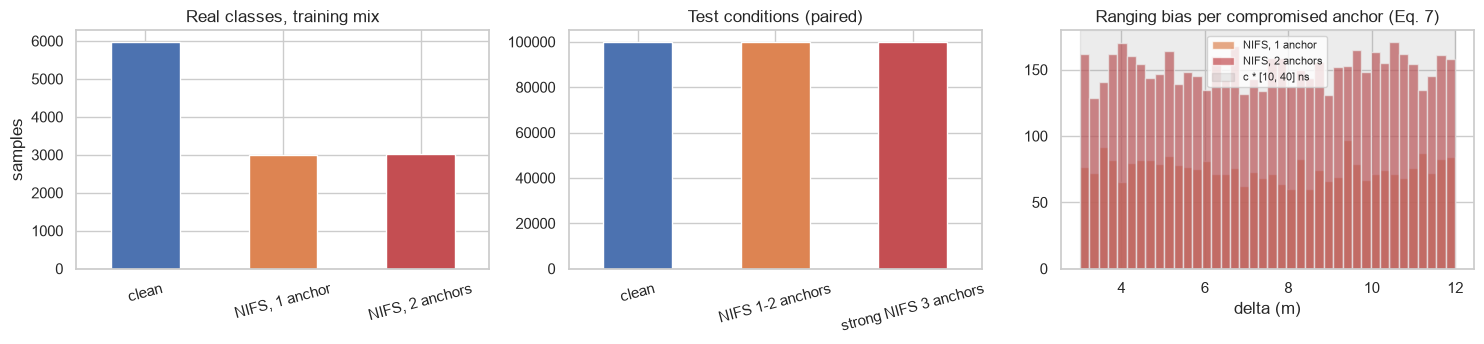

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
cnt.plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452", "#C44E52"], rot=15); ax[0].set_title("Real classes, training mix"); ax[0].set_ylabel("samples")
ev = pd.Series({"clean": len(TE["pos"]), "NIFS 1-2 anchors": len(TE["pos"]), "strong NIFS 3 anchors": len(TE["pos"])})
ev.plot.bar(ax=ax[1], color=["#4C72B0", "#DD8452", "#C44E52"], rot=15); ax[1].set_title("Test conditions (paired)")
for lab, c in zip([1, 2], ["#DD8452", "#C44E52"]):
    b = (TR["m"] - TR["m_clean"])[TR["label"] == lab]; b = b[b > 0]
    ax[2].hist(b, bins=40, alpha=.7, color=c, label=lab_names[lab])
ax[2].axvspan(C_LIGHT * DT_NS_TRAIN[0] * 1e-9, C_LIGHT * DT_NS_TRAIN[1] * 1e-9, color="grey", alpha=.15, label="c * [10, 40] ns")
ax[2].set_title("Ranging bias per compromised anchor (Eq. 7)"); ax[2].set_xlabel("delta (m)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

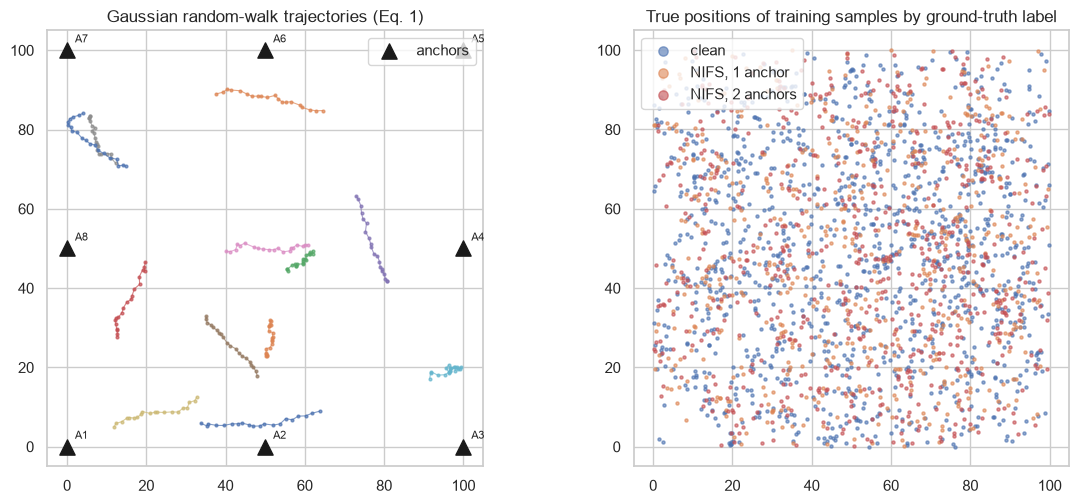

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
for nd in range(0, N_TRAIN_NODES, max(1, N_TRAIN_NODES // 12)):
    p = TR["pos"][TR["node"] == nd]; ax[0].plot(p[:, 0], p[:, 1], "-o", ms=2, lw=.8, alpha=.7)
ax[0].scatter(ANCH[:, 0], ANCH[:, 1], marker="^", s=120, c="k", label="anchors")
for i, a in enumerate(ANCH): ax[0].annotate(f"A{i + 1}", a + 2, fontsize=8)
ax[0].set_title("Gaussian random-walk trajectories (Eq. 1)"); ax[0].set_xlim(-5, AREA + 5); ax[0].set_ylim(-5, AREA + 5); ax[0].legend(); ax[0].set_aspect("equal")
sub = rng.choice(len(TR["pos"]), min(2500, len(TR["pos"])), replace=False)
for lab, c in zip([0, 1, 2], ["#4C72B0", "#DD8452", "#C44E52"]):
    s = sub[TR["label"][sub] == lab]; ax[1].scatter(TR["pos"][s, 0], TR["pos"][s, 1], s=5, c=c, alpha=.6, label=lab_names[lab])
ax[1].set_title("True positions of training samples by ground-truth label"); ax[1].legend(markerscale=3); ax[1].set_aspect("equal")
plt.tight_layout(); plt.show()

**Scatter plots of the real (simulated) observations coloured by their ground-truth label.** First the raw PCA coordinates of the 8-dimensional range vectors (PCA fitted on the training split only), then the same two coordinates scaled to `[0, pi]`, the range of a rotation angle (the angle-encoding view; scaler fitted on training data, test angles would be clipped). The honest picture is that the three classes overlap almost completely in the leading components: the range vector mostly encodes *where the node is*, not whether an anchor lied. The second figure shows where the attack *is* visible, in the geometric inconsistency of the ranges.

explained variance of the first components: [0.471 0.459 0.035 0.016]


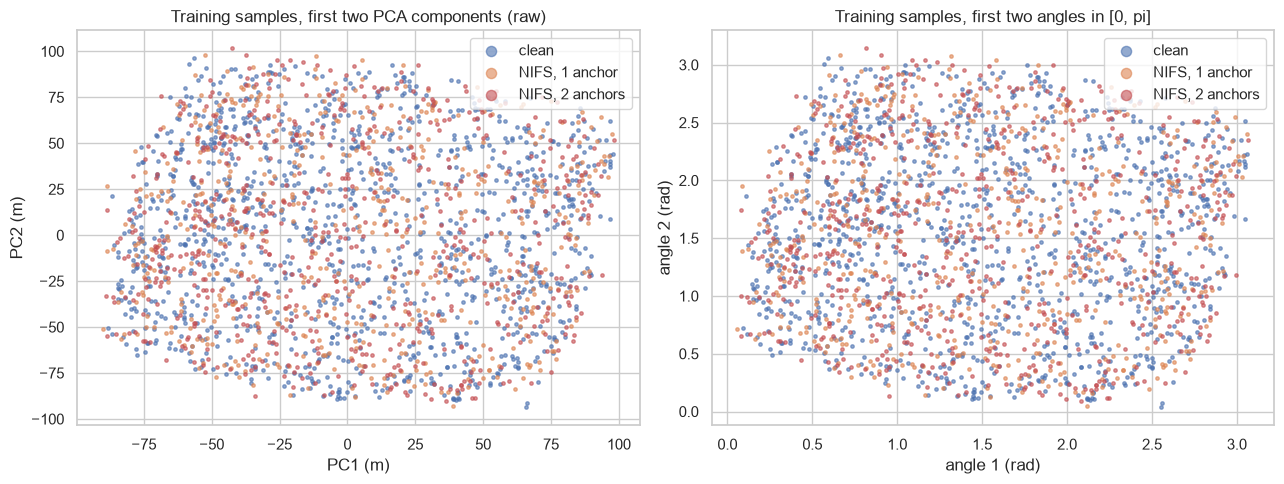

The attack barely moves the points in the first two components: the distance vector is dominated by WHERE the node is, not by whether an anchor lies. A model has to use all eight coordinates and their geometric consistency to see the attack.


In [8]:
# Raw PCA coordinates of the measurement vectors (fitted on the TRAINING split only), coloured by the real label
pca = PCA(n_components=N_ANCH, random_state=SEED).fit(TR["m"])
print("explained variance of the first components:", np.round(pca.explained_variance_ratio_[:4], 3))
Ptr = pca.transform(TR["m"]); Pte = pca.transform(TE["m_nifs"])
cols = {0: "#4C72B0", 1: "#DD8452", 2: "#C44E52"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for lab in [0, 1, 2]:
    s = sub[TR["label"][sub] == lab]; ax[0].scatter(Ptr[s, 0], Ptr[s, 1], s=6, c=cols[lab], alpha=.6, label=lab_names[lab])
ax[0].set_title("Training samples, first two PCA components (raw)"); ax[0].set_xlabel("PC1 (m)"); ax[0].set_ylabel("PC2 (m)"); ax[0].legend(markerscale=3)
# the same coordinates scaled to [0, pi]: the angle range of an angle-encoded circuit (scaler fitted on the training split, test angles clipped)
sc = MinMaxScaler((0, np.pi)).fit(Ptr[:, :2])
A = np.clip(sc.transform(Ptr[:, :2]), 0, np.pi)
for lab in [0, 1, 2]:
    s = sub[TR["label"][sub] == lab]; ax[1].scatter(A[s, 0], A[s, 1], s=6, c=cols[lab], alpha=.6, label=lab_names[lab])
ax[1].set_title("Training samples, first two angles in [0, pi]"); ax[1].set_xlabel("angle 1 (rad)"); ax[1].set_ylabel("angle 2 (rad)"); ax[1].legend(markerscale=3)
plt.tight_layout(); plt.show()
print("The attack barely moves the points in the first two components: the distance vector is dominated by WHERE the node is, "
      "not by whether an anchor lies. A model has to use all eight coordinates and their geometric consistency to see the attack.")

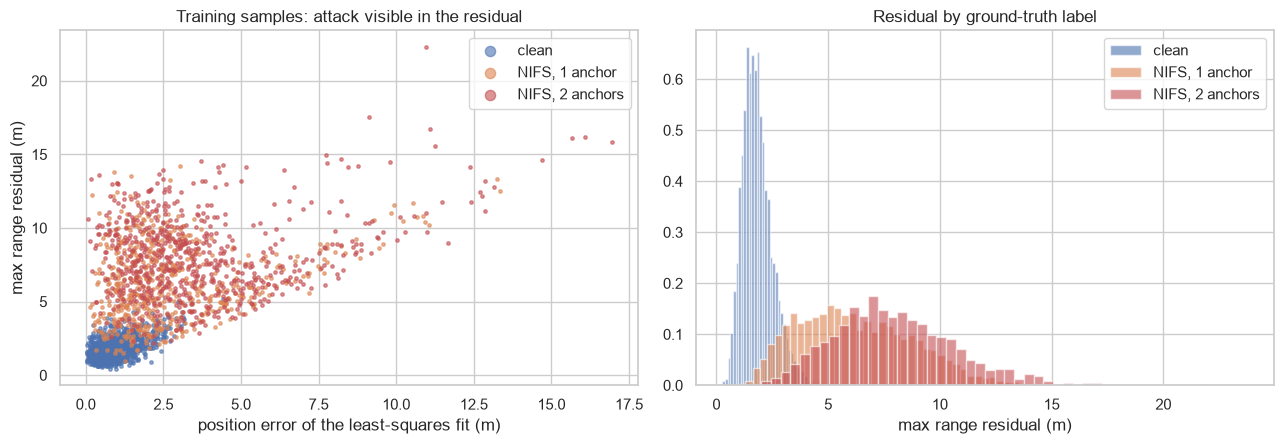

In [9]:
# Where the attack becomes visible: the geometric inconsistency of the ranges. Residual of the LEAST-SQUARES position fit,
# max_i | d_i - |x_ls - a_i| |, coloured by label, against the true position error of that fit.
def ls_np(m):
    A_ = 2 * (ANCH[1:] - ANCH[0]); b_ = (ANCH[1:] ** 2).sum(1) - (ANCH[0] ** 2).sum() - (m[:, 1:] ** 2 - m[:, [0]] ** 2)
    return b_ @ np.linalg.pinv(A_).T
x_ls = ls_np(TR["m"]); res = np.abs(TR["m"] - np.linalg.norm(x_ls[:, None] - ANCH[None], axis=2)).max(1)
err_ls = np.linalg.norm(x_ls - TR["pos"], axis=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for lab in [0, 1, 2]:
    s = sub[TR["label"][sub] == lab]; ax[0].scatter(err_ls[s], res[s], s=6, c=cols[lab], alpha=.6, label=lab_names[lab])
ax[0].set_xlabel("position error of the least-squares fit (m)"); ax[0].set_ylabel("max range residual (m)"); ax[0].legend(markerscale=3)
ax[0].set_title("Training samples: attack visible in the residual")
for lab in [0, 1, 2]: ax[1].hist(res[TR["label"] == lab], bins=50, alpha=.6, color=cols[lab], label=lab_names[lab], density=True)
ax[1].set_xlabel("max range residual (m)"); ax[1].set_title("Residual by ground-truth label"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. The four models of the paper

All four share one CNN head (the baseline `CNN` is exactly the head on the raw ranges), so the comparison isolates what the paper claims to add:

| Model | Input to the CNN | Extra stage |
|---|---|---|
| CNN (Eqs. 10-11) | ranges `m / 100` | none |
| CNN-KMeans (Eqs. 12-13) | ranges | K-Means on `m`, one CNN branch per cluster |
| HQC-NN (Eqs. 14-16) | quantum features `z` (8 values in [-1, 1]) | 8-qubit parameterised circuit, trained end to end |
| HQC-NN-KMeans (Eq. 17) | quantum features | K-Means on `z`, one CNN branch per cluster |

For speed the 8-qubit circuit is simulated **exactly** by a small PyTorch state-vector routine (the whole variational unitary is built once per batch from the rotation gates and a CNOT permutation). The next section draws the *real* PennyLane QNode of the same circuit and asserts that the two agree to float precision, in outputs and in gradients; after training, the trained models are re-evaluated through the real QNode (Section 6).

In [10]:
# ---------------- exact fast simulator of the SAME circuit (used for training; asserted equal to the QNode above) ----------------
def _rot(phi, theta, omega):
    """PennyLane Rot(phi, theta, omega) as a (..., 2, 2) complex matrix."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    ep = torch.exp(-0.5j * (phi + omega)); em = torch.exp(0.5j * (phi - omega))
    return torch.stack([torch.stack([ep * c, -em * s], -1), torch.stack([em.conj() * s, ep.conj() * c], -1)], -2)

def _cnot_ring_perm(n, r):
    f = np.zeros(2 ** n, dtype=np.int64)
    for j in range(2 ** n):
        bits = [(j >> (n - 1 - q)) & 1 for q in range(n)]            # wire 0 = most significant bit (PennyLane convention)
        for c in range(n):
            t = (c + r) % n
            if bits[c]: bits[t] ^= 1
        f[j] = sum(b << (n - 1 - q) for q, b in enumerate(bits))
    finv = np.zeros_like(f); finv[f] = np.arange(2 ** n)
    return torch.tensor(finv)

_PERMS = {}
_ZSIGN = torch.tensor([[1 - 2 * ((j >> (N_ANCH - 1 - q)) & 1) for q in range(N_ANCH)] for j in range(2 ** N_ANCH)], dtype=torch.float32)

def variational_unitary(weights):
    """Unitary of StronglyEntanglingLayers: Rot gates contracted into the identity, the CNOT ring (range r = l % (n-1) + 1) as a row permutation."""
    n = N_ANCH; w = weights.to(torch.float32)
    R = _rot(w[..., 0], w[..., 1], w[..., 2])
    U = torch.eye(2 ** n, dtype=torch.complex64).reshape([2] * n + [2 ** n])
    for l in range(w.shape[0]):
        for q in range(n):
            U = torch.movedim(torch.tensordot(R[l, q], U, dims=([1], [q])), 0, q)
        r = (l % (n - 1)) + 1
        if (n, r) not in _PERMS: _PERMS[(n, r)] = _cnot_ring_perm(n, r)
        U = U.reshape(2 ** n, 2 ** n)[_PERMS[(n, r)]].reshape([2] * n + [2 ** n])
    return U.reshape(2 ** n, 2 ** n)

def fast_circuit(x, weights, phi):
    B = x.shape[0]; n = N_ANCH
    a = x.to(torch.float32) * phi.to(torch.float32)
    psi = torch.stack([torch.cos(a / 2).to(torch.complex64), -1j * torch.sin(a / 2)], dim=-1)    # RX(a)|0> per qubit
    s = psi[:, 0]
    for i in range(1, n):
        s = s.unsqueeze(-1) * psi[:, i].view(B, *([1] * i), 2)
    s = s.reshape(B, -1) @ variational_unitary(weights).T
    return (s.real ** 2 + s.imag ** 2) @ _ZSIGN

class FastQLayer(nn.Module):
    """Quantum feature extractor (trainable circuit weights and feature-map scales phi_i); output z in [-1, 1]^8."""
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.rand(N_LAYERS, N_ANCH, 3) * 2 * np.pi * 0.1)          # CHOICE: small random start
        self.phi = nn.Parameter(torch.full((N_ANCH,), float(np.pi)))                           # CHOICE: d/AREA in [0,1] -> angle in [0, pi]
    def forward(self, x):
        return fast_circuit(x, self.weights, self.phi).to(x.dtype)

class QNodeLayer(nn.Module):
    """The same layer evaluated through the real PennyLane QNode (used only for the equivalence checks)."""
    def __init__(self, fast):
        super().__init__(); self.weights = fast.weights; self.phi = fast.phi
    def forward(self, x):
        return torch.stack(list(circuit(x, self.weights, self.phi)), dim=-1).to(x.dtype)

def cnn_head():
    """Compact 1-D CNN (Eq. 10 / 16): conv-conv-dense over the 8 anchor channels, output = (x, y) / AREA."""
    return nn.Sequential(nn.Unflatten(1, (1, N_ANCH)), nn.Conv1d(1, 16, 3, padding=1), nn.ReLU(),
                         nn.Conv1d(16, 32, 3, padding=1), nn.ReLU(), nn.Flatten(),
                         nn.Linear(32 * N_ANCH, 64), nn.ReLU(), nn.Linear(64, 2))

class Localizer(nn.Module):
    """front = identity (CNN) or quantum layer (HQC-NN); head = CNN; optionally K cluster-specific CNN branches (Eqs. 13, 17)."""
    def __init__(self, quantum):
        super().__init__()
        self.front = FastQLayer() if quantum else nn.Identity()
        self.head = cnn_head(); self.branches = None; self.km = None
    def forward(self, x):
        z = self.front(x)
        if self.branches is None:
            return self.head(z)
        c = torch.as_tensor(self.km.predict(z.detach().numpy().astype(np.float64)))           # c(z) in {0..K-1}: hard routing
        out = torch.zeros(len(z), 2, dtype=z.dtype)
        for k, br in enumerate(self.branches):
            idx = torch.nonzero(c == k).squeeze(1)
            if len(idx): out = out.index_put((idx,), br(z[idx]))
        return out

def fit(model, X, Y, Xv, Yv, epochs, lr, lr_q=None, bs=BATCH, verbose=True, tag=""):
    """Adam on the MSE of Eq. (11); the epoch with the lowest validation MSE is kept (CHOICE)."""
    groups = [{"params": [p for n_, p in model.named_parameters() if p.requires_grad and not n_.startswith("front")], "lr": lr}]
    qp = [p for n_, p in model.named_parameters() if p.requires_grad and n_.startswith("front")]
    if qp: groups.append({"params": qp, "lr": lr_q or lr})
    opt = torch.optim.Adam(groups); best, hist = (1e9, None), []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X)); tl = 0.0
        for i in range(0, len(X), bs):
            b = perm[i:i + bs]; opt.zero_grad()
            loss = ((model(X[b]) - Y[b]) ** 2).mean(); loss.backward(); opt.step(); tl += loss.item() * len(b)
        model.eval()
        with torch.no_grad(): v = ((model(Xv) - Yv) ** 2).mean().item()
        hist.append((np.sqrt(tl / len(X)) * AREA, np.sqrt(v) * AREA))
        if v < best[0]: best = (v, copy.deepcopy(model.state_dict()))
    model.load_state_dict(best[1]); model.eval()
    if verbose: print(f"  {tag:14s} best validation RMSE {np.sqrt(best[0]) * AREA:5.2f} m after {epochs} epochs")
    return hist

def kmeans_variant(base, Xtr, Ytr, Xva, Yva, seed, tag):
    """CNN-KMeans / HQC-NN-KMeans: cluster the (quantum) feature vectors, then fine-tune one copy of the CNN per cluster on its own data.
    CHOICE: the quantum layer of HQC-NN is frozen after its end-to-end training; branches start from the trained global CNN."""
    km_model = copy.deepcopy(base)
    for p in km_model.front.parameters(): p.requires_grad = False
    with torch.no_grad(): Ztr, Zva = km_model.front(Xtr), km_model.front(Xva)
    km = KMeans(n_clusters=K_CLUSTERS, n_init=10, random_state=seed).fit(Ztr.numpy().astype(np.float64))
    km_model.km = km; ctr = torch.as_tensor(km.labels_); cva = torch.as_tensor(km.predict(Zva.numpy().astype(np.float64)))
    km_model.branches = nn.ModuleList()
    for k in range(K_CLUSTERS):
        br = copy.deepcopy(base.head); itr, iva = ctr == k, cva == k
        if iva.sum() < 5: iva = torch.ones_like(cva, dtype=torch.bool)
        if itr.sum() >= 5:
            fit(br, Ztr[itr], Ytr[itr], Zva[iva], Yva[iva], EPOCHS_BRANCH, LR * 0.5, verbose=False)
        km_model.branches.append(br)
    km_model.eval(); sizes = np.bincount(km.labels_, minlength=K_CLUSTERS)
    print(f"  {tag:14s} K-Means cluster sizes {sizes.tolist()}")
    return km_model

def to_t(m): return torch.tensor(m / AREA, dtype=torch.float32)                 # network input: ranges / AREA
def predict(model, m, bs=4000):
    """Position estimates in metres for a (n, 8) array of ranges (metres)."""
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(m), bs): out.append(model(to_t(m[i:i + bs])).numpy())
    return np.concatenate(out) * AREA

## Quantum Circuit Architecture

The quantum part of HQC-NN and of HQC-NN-KMeans is **one and the same circuit** (K-Means only changes the classical head), so there is a single architecture to draw. The cell defines the actual PennyLane QNode, draws it with `qml.draw_mpl`, and prints qubits, depth and trainable parameters. Where the paper is silent we choose (`# CHOICE:`):

- **Qubits.** One per anchor (8): the paper encodes the whole measurement vector `m` in `|psi(m)> = U_phi(m)|0>^n`, so `n = N`.
- **Feature map `U_phi`.** `RX(phi_i * d_i / 100)` on qubit `i`, with trainable `phi_i` (initialised to pi so that the 0-100 m range maps to 0-pi). The paper says only that `phi` are trainable parameters of the feature map.
- **Variational circuit `U(theta)`.** Two `StronglyEntanglingLayers` (a general rotation `Rot(a, b, c)` on every qubit followed by a CNOT ring; range 1 in layer 1, range 2 in layer 2). The paper names no ansatz.
- **Measurement.** `<Z_k>` on every qubit, giving `z` with 8 entries (the paper writes `K+1` Pauli operators without saying which).

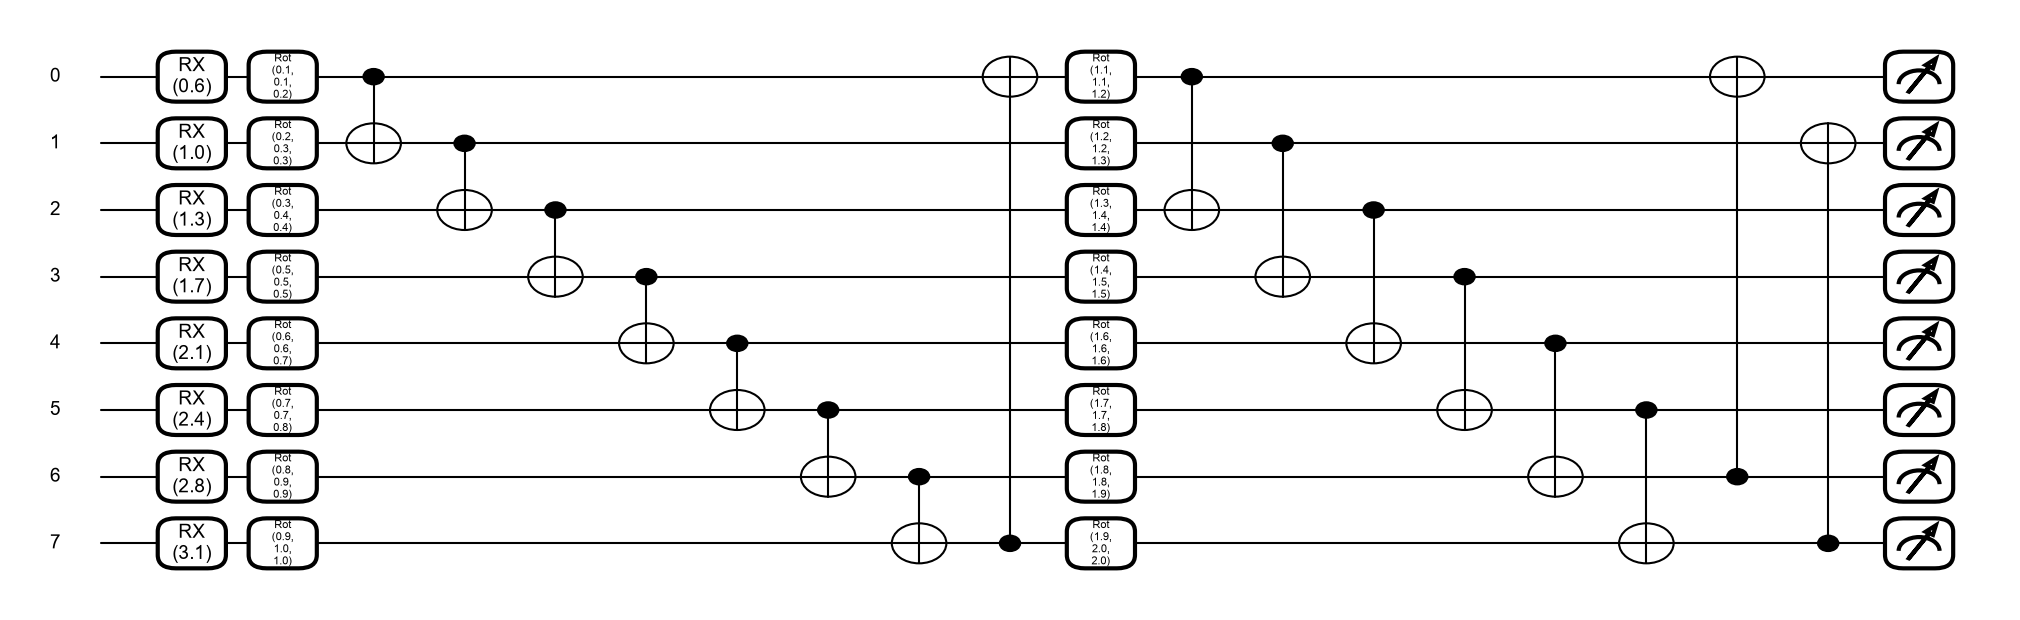

In [11]:
# The quantum feature extractor U_phi(m), U(theta) of Eqs. (14)-(15): one qubit per anchor. The drawing is the executed circuit decomposed to RX, Rot and CNOT gates.
dev = qml.device("default.qubit", wires=N_ANCH)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def circuit(inputs, weights, phi):
    qml.AngleEmbedding(inputs * phi, wires=range(N_ANCH), rotation="X")          # feature map U_phi(m): RX(phi_i * d_i / AREA)
    qml.StronglyEntanglingLayers(weights, wires=range(N_ANCH))                  # variational circuit U(theta)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_ANCH)]                   # z_k = <Z_k>, Eq. (15)

x_demo = torch.linspace(0.2, 1.0, N_ANCH)                                         # one normalised distance vector d / AREA
w_demo = torch.linspace(0.1, 2.0, N_LAYERS * N_ANCH * 3).reshape(N_LAYERS, N_ANCH, 3)
phi_demo = torch.full((N_ANCH,), float(np.pi))
fig, ax = qml.draw_mpl(circuit, decimals=1, level="device")(x_demo, w_demo, phi_demo)
fig.set_size_inches(20, 6); plt.show()

In [12]:
try:
    sp = qml.specs(circuit, level="device")(x_demo, w_demo, phi_demo)
except Exception:
    sp = qml.specs(circuit)(x_demo, w_demo, phi_demo)
res_ = sp["resources"] if isinstance(sp, dict) else sp.resources
depth = res_.depth
n_q_params = N_LAYERS * N_ANCH * 3 + N_ANCH                                       # StronglyEntanglingLayers weights + trainable phi_i
print(f"qubits            : {N_ANCH}  (one per anchor)")
print(f"circuit depth     : {depth}  (after decomposition to the device gate set)")
print(f"gate counts       : {dict(res_.gate_types)}")
print(f"trainable params  : {n_q_params}  = {N_LAYERS} layers x {N_ANCH} qubits x 3 rotation angles + {N_ANCH} feature-map scales phi_i")
print("measurement       : <Z> on every qubit -> 8 quantum features z, passed to the CNN")

qubits            : 8  (one per anchor)
circuit depth     : 15  (after decomposition to the device gate set)
gate counts       : {'RX': 8, 'Rot': 16, 'CNOT': 16}
trainable params  : 56  = 2 layers x 8 qubits x 3 rotation angles + 8 feature-map scales phi_i
measurement       : <Z> on every qubit -> 8 quantum features z, passed to the CNN


In [13]:
# Equivalence of the fast training simulator with the real QNode: outputs AND gradients, random inputs and weights
torch.manual_seed(0)
xb = torch.rand(32, N_ANCH); pb = torch.rand(N_ANCH) * 3
wb1 = (torch.rand(N_LAYERS, N_ANCH, 3) * 6).requires_grad_(True); wb2 = wb1.detach().clone().requires_grad_(True)
z_qnode = torch.stack(list(circuit(xb, wb1, pb)), dim=-1); z_fast = fast_circuit(xb, wb2, pb)
z_qnode.pow(2).sum().backward(); z_fast.pow(2).sum().backward()
print("max |z_fast - z_qnode|           :", float((z_qnode - z_fast).abs().max()))
print("max |grad_fast - grad_qnode| (theta):", float((wb1.grad - wb2.grad).abs().max()))
assert torch.allclose(z_qnode.float(), z_fast, atol=1e-5) and torch.allclose(wb1.grad.float(), wb2.grad, atol=1e-4)
n_cnn = sum(p.numel() for p in cnn_head().parameters())
print(f"CNN head parameters: {n_cnn} | quantum layer parameters: {N_LAYERS * N_ANCH * 3 + N_ANCH} | HQC-NN total: {n_cnn + N_LAYERS * N_ANCH * 3 + N_ANCH}")

max |z_fast - z_qnode|           : 2.5366016515038226e-07
max |grad_fast - grad_qnode| (theta): 2.1532177925109863e-06
CNN head parameters: 18210 | quantum layer parameters: 56 | HQC-NN total: 18266


## 3. Classical references on identical inputs

Before any quantum model: **least-squares multilateration** (the textbook estimator, which has no defence against a biased anchor), a **Random Forest** and an **RBF support-vector regressor**, all fed with the same 8 ranges, trained on the same clean/attacked mix. The Random Forest and SVR are the generic learning baselines required for every notebook of this project; the paper compares only against a CNN.

In [14]:
# ---- classical references on identical inputs: least-squares multilateration, Random Forest, SVR(rbf) ----
ANCH_T = torch.tensor(ANCH, dtype=torch.float32)
def ls_torch(m):
    """Linearised least-squares multilateration (differentiable); m in metres."""
    A_ = 2 * (ANCH_T[1:] - ANCH_T[0]); b_ = (ANCH_T[1:] ** 2).sum(1) - (ANCH_T[0] ** 2).sum() - (m[:, 1:] ** 2 - m[:, [0]] ** 2)
    return b_ @ torch.linalg.pinv(A_).T
class LSModel(nn.Module):
    def forward(self, x): return ls_torch(x * AREA) / AREA

def errs(pred, pos): return np.linalg.norm(pred - pos, axis=1)
def summarize(pred, pos):
    e = errs(pred, pos)
    return dict(RMSE=float(np.sqrt((e ** 2).mean())), mean=float(e.mean()), p90=float(np.percentile(e, 90)))

CONDS = {"clean": "m_clean", "NIFS": "m_nifs", "strong NIFS": "m_strong"}
def evaluate(predict_fn):
    return {c: summarize(predict_fn(TE[k]), TE["pos"]) for c, k in CONDS.items()}

def fit_sklearn(seed):
    out = {}
    rf = RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=2, n_jobs=2, random_state=seed).fit(TR["m"] / AREA, TR["pos"] / AREA)
    out["RandomForest"] = lambda m, rf=rf: rf.predict(m / AREA) * AREA
    svr = MultiOutputRegressor(SVR(kernel="rbf", C=10.0, epsilon=0.01, gamma="scale")).fit(TR["m"] / AREA, TR["pos"] / AREA)
    out["SVR (rbf)"] = lambda m, svr=svr: svr.predict(m / AREA) * AREA
    return out
ls_model = LSModel()
ls_fn = lambda m: predict(ls_model, m)
print("least-squares multilateration, clean:", summarize(ls_fn(TE["m_clean"]), TE["pos"]), "\n                          NIFS :", summarize(ls_fn(TE["m_nifs"]), TE["pos"]))

least-squares multilateration, clean: {'RMSE': 1.083932468501581, 'mean': 0.9349096583746499, 'p90': 1.662744445572419} 
                          NIFS : {'RMSE': 3.9591891940725397, 'mean': 3.1417336686197097, 'p90': 6.283129743423222}


## 4. Training

For each seed: train the CNN, derive CNN-KMeans, train the HQC-NN end to end (Adam; circuit weights and the feature-map scales `phi` get a larger learning rate), derive HQC-NN-KMeans. The validation set picks the best epoch. All data are simulated once (fixed `SEED`); the seeds vary the initialisation, the shuffling and K-Means.

In [15]:
XTR, YTR = to_t(TR["m"]), torch.tensor(TR["pos"] / AREA, dtype=torch.float32)
XVA, YVA = to_t(VA["m"]), torch.tensor(VA["pos"] / AREA, dtype=torch.float32)
MODEL_NAMES = ["CNN", "CNN-KMeans", "HQC-NN", "HQC-NN-KMeans"]
MODELS, HIST, RESULTS, TRAIN_TIME = {}, {}, {}, {}
for seed in SEEDS:
    print(f"=== seed {seed} ===")
    set_seed(seed); t0 = time.time()
    cnn = Localizer(False); h_cnn = fit(cnn, XTR, YTR, XVA, YVA, EPOCHS, LR, tag="CNN")
    cnn_km = kmeans_variant(cnn, XTR, YTR, XVA, YVA, seed, "CNN-KMeans")
    t1 = time.time()
    set_seed(seed)
    hqc = Localizer(True); h_hqc = fit(hqc, XTR, YTR, XVA, YVA, EPOCHS, LR, LR_Q, tag="HQC-NN")
    hqc_km = kmeans_variant(hqc, XTR, YTR, XVA, YVA, seed, "HQC-NN-KMeans")
    TRAIN_TIME[seed] = (t1 - t0, time.time() - t1)
    MODELS[seed] = dict(zip(MODEL_NAMES, [cnn, cnn_km, hqc, hqc_km])); HIST[seed] = dict(CNN=h_cnn, **{"HQC-NN": h_hqc})
    R = {n: evaluate(lambda m, mod=mod: predict(mod, m)) for n, mod in MODELS[seed].items()}
    R["LS multilateration"] = evaluate(ls_fn)
    for n, fn in fit_sklearn(seed).items(): R[n] = evaluate(fn)
    RESULTS[seed] = R
    print(f"  training time: CNN family {TRAIN_TIME[seed][0]:.0f} s, HQC family {TRAIN_TIME[seed][1]:.0f} s")

=== seed 42 ===


  CNN            best validation RMSE  1.21 m after 30 epochs


  CNN-KMeans     K-Means cluster sizes [2860, 3420, 3282, 2438]


  HQC-NN         best validation RMSE  1.52 m after 30 epochs


  HQC-NN-KMeans  K-Means cluster sizes [3376, 2340, 4255, 2029]


...

  CNN            best validation RMSE  1.07 m after 30 epochs


  CNN-KMeans     K-Means cluster sizes [2891, 3413, 3262, 2434]


  HQC-NN         best validation RMSE  1.60 m after 30 epochs


  HQC-NN-KMeans  K-Means cluster sizes [4553, 1907, 2779, 2761]


  training time: CNN family 106 s, HQC family 519 s


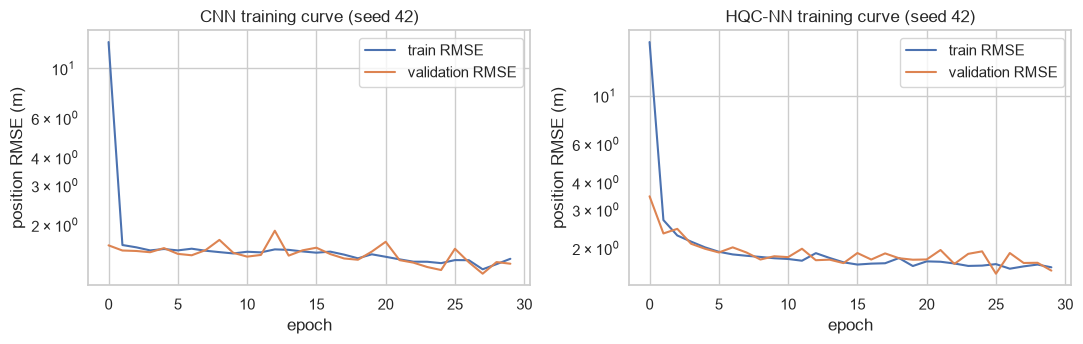

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); s0 = SEEDS[0]
for a, n in zip(ax, ["CNN", "HQC-NN"]):
    h = np.array(HIST[s0][n]); a.plot(h[:, 0], label="train RMSE"); a.plot(h[:, 1], label="validation RMSE")
    a.set_title(f"{n} training curve (seed {s0})"); a.set_xlabel("epoch"); a.set_ylabel("position RMSE (m)"); a.set_yscale("log"); a.legend()
plt.tight_layout(); plt.show()

## 5. Localisation error, with and without the NIFS attack

RMSE of the position estimate in metres on the test nodes, in three conditions: no attack, the NIFS attack the models were trained against (1-2 anchors, 10-40 ns) and an unseen stronger one (3 anchors, 30-80 ns). Lower is better. Mean and 90th percentile errors follow.

In [17]:
ORDER = ["LS multilateration", "RandomForest", "SVR (rbf)"] + MODEL_NAMES
def agg(metric):
    rows = {}
    for n in ORDER:
        rows[n] = {}
        for c in CONDS:
            v = np.array([RESULTS[s][n][c][metric] for s in SEEDS])
            rows[n][c] = f"{v.mean():.2f}" + (f" +/- {v.std():.2f}" if len(SEEDS) > 1 else "")
    return pd.DataFrame(rows).T
print(f"Localisation RMSE in metres on the {len(TE['pos'])} test samples (mean +/- std over seeds {SEEDS}):")
display(agg("RMSE"))
print("Mean Euclidean error (m):"); display(agg("mean"))
print("90th percentile error (m):"); display(agg("p90"))

Localisation RMSE in metres on the 100000 test samples (mean +/- std over seeds [42, 43, 44]):


,clean,NIFS,strong NIFS
LS multilateration,1.08 +/- 0.00,3.96 +/- 0.00,11.35 +/- 0.00
RandomForest,1.05 +/- 0.00,2.16 +/- 0.01,7.44 +/- 0.05
SVR (rbf),0.78 +/- 0.00,1.42 +/- 0.00,6.13 +/- 0.00
CNN,0.97 +/- 0.03,1.98 +/- 0.16,6.02 +/- 0.23
CNN-KMeans,0.94 +/- 0.04,1.80 +/- 0.11,5.74 +/- 0.12
HQC-NN,1.42 +/- 0.02,2.82 +/- 0.07,7.79 +/- 0.14
HQC-NN-KMeans,1.25 +/- 0.04,2.66 +/- 0.06,7.57 +/- 0.15


Mean Euclidean error (m):


,clean,NIFS,strong NIFS
LS multilateration,0.93 +/- 0.00,3.14 +/- 0.00,10.04 +/- 0.00
RandomForest,0.90 +/- 0.00,1.79 +/- 0.00,6.02 +/- 0.02
SVR (rbf),0.69 +/- 0.00,1.20 +/- 0.00,5.22 +/- 0.00
CNN,0.85 +/- 0.02,1.71 +/- 0.15,5.34 +/- 0.24
CNN-KMeans,0.83 +/- 0.03,1.53 +/- 0.11,5.02 +/- 0.13
HQC-NN,1.22 +/- 0.01,2.47 +/- 0.06,6.95 +/- 0.11
HQC-NN-KMeans,1.09 +/- 0.04,2.32 +/- 0.05,6.76 +/- 0.13


90th percentile error (m):


,clean,NIFS,strong NIFS
LS multilateration,1.66 +/- 0.00,6.28 +/- 0.00,17.49 +/- 0.00
RandomForest,1.56 +/- 0.01,3.36 +/- 0.01,11.97 +/- 0.08
SVR (rbf),1.18 +/- 0.00,2.19 +/- 0.00,9.69 +/- 0.00
CNN,1.47 +/- 0.04,3.09 +/- 0.23,9.12 +/- 0.33
CNN-KMeans,1.43 +/- 0.06,2.81 +/- 0.18,8.77 +/- 0.17
HQC-NN,2.13 +/- 0.03,4.32 +/- 0.10,11.69 +/- 0.25
HQC-NN-KMeans,1.90 +/- 0.07,4.08 +/- 0.09,11.38 +/- 0.25


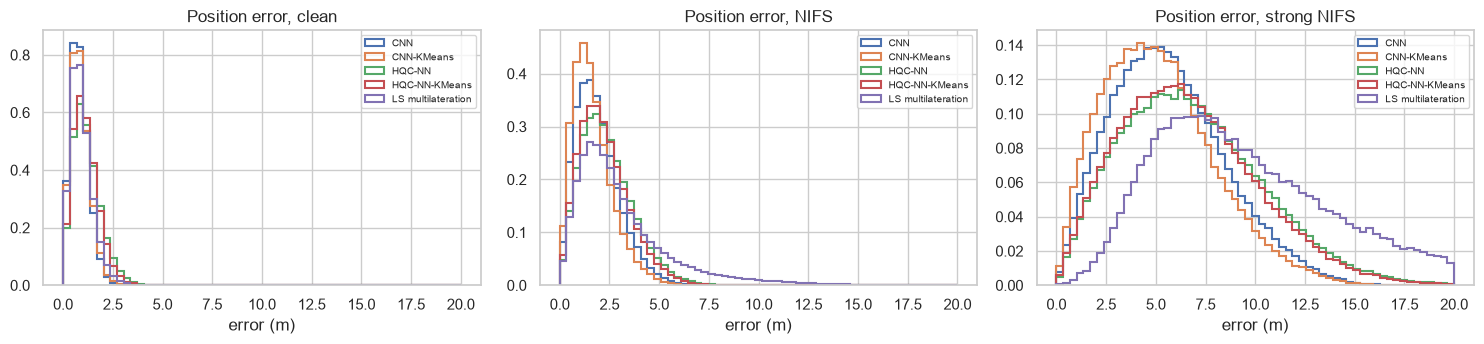

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6)); s0 = SEEDS[0]
for a, (c, k) in zip(ax, CONDS.items()):
    for n in MODEL_NAMES + ["LS multilateration"]:
        e = errs(predict(MODELS[s0][n], TE[k]) if n in MODELS[s0] else ls_fn(TE[k]), TE["pos"])
        a.hist(e, bins=np.linspace(0, 20, 60), histtype="step", lw=1.5, label=n, density=True)
    a.set_title(f"Position error, {c}"); a.set_xlabel("error (m)"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. Detection accuracy factor (DAF) and attack detection

The paper plots a "DAF" that is 1.0 for the CNN and up to 1.6 for HQC-NN-KMeans, without defining it. We keep the property that the CNN equals 1 and define DAF as the **attack-error ratio** to the CNN (see the table at the top). Because the name says *detection*, we also report a simple **model-assisted detector**: the model's position estimate predicts the eight ranges, and the largest range residual is the attack score. A model that is robust to the delayed anchors leaves that anchor's delay visible as a large residual, whereas least squares spreads the bias over all residuals and hides it.

The cell after the metrics re-evaluates the trained HQC models through the **real PennyLane QNode**.

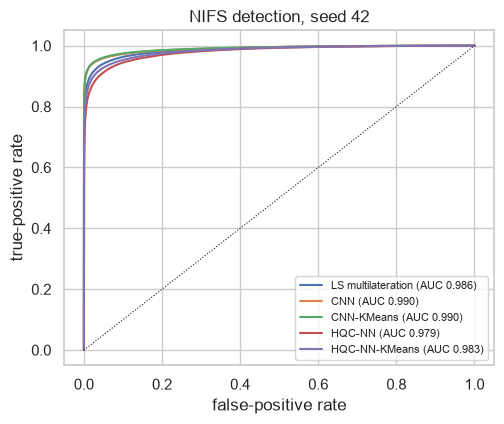

,DAF (attack-RMSE ratio to CNN),detection AUC (seed 42),TPR at 5% FPR (seed 42)
CNN,1.00 +/- 0.00,0.990,0.96
CNN-KMeans,1.10 +/- 0.02,0.990,0.96
HQC-NN,0.70 +/- 0.07,0.979,0.91
HQC-NN-KMeans,0.75 +/- 0.08,0.983,0.93


In [19]:
# Attack detection (the "D" of DAF): a model-assisted consistency test. The model's own position estimate is used to predict the
# 8 ranges; the score is the largest range residual. A model whose estimate is robust to the attack leaves the delayed range as a large residual.
def residual_score(m, pos_hat): return np.abs(m - np.linalg.norm(pos_hat[:, None] - ANCH[None], axis=2)).max(1)
def detection(predict_fn):
    s0, s1 = residual_score(TE["m_clean"], predict_fn(TE["m_clean"])), residual_score(TE["m_nifs"], predict_fn(TE["m_nifs"]))
    y = np.r_[np.zeros(len(s0)), np.ones(len(s1))]; sc_ = np.r_[s0, s1]
    fpr, tpr, _ = roc_curve(y, sc_)
    return roc_auc_score(y, sc_), float(np.interp(0.05, fpr, tpr)), (fpr, tpr)
DET = {}
det_models = {"LS multilateration": ls_fn, **{n: (lambda m, mod=mod: predict(mod, m)) for n, mod in MODELS[SEEDS[0]].items()}}
for n, fn in det_models.items(): DET[n] = detection(fn)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for n, (auc, tpr5, (fpr, tpr)) in DET.items(): ax.plot(fpr, tpr, label=f"{n} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=.8); ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.set_title(f"NIFS detection, seed {SEEDS[0]}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# DAF: the paper never defines it beyond "ability to identify and mitigate attacks while keeping accuracy" and plots it relative to the CNN (=1).
# CHOICE: DAF = (attack RMSE of the baseline CNN) / (attack RMSE of the model), per seed; > 1 means better mitigation than the CNN.
def daf(seed, n): return RESULTS[seed]["CNN"]["NIFS"]["RMSE"] / RESULTS[seed][n]["NIFS"]["RMSE"]
DAF = {n: np.array([daf(s, n) for s in SEEDS]) for n in MODEL_NAMES}
tab = pd.DataFrame({"DAF (attack-RMSE ratio to CNN)": {n: f"{v.mean():.2f}" + (f" +/- {v.std():.2f}" if len(SEEDS) > 1 else "") for n, v in DAF.items()},
                    f"detection AUC (seed {SEEDS[0]})": {n: f"{DET[n][0]:.3f}" for n in MODEL_NAMES},
                    f"TPR at 5% FPR (seed {SEEDS[0]})": {n: f"{DET[n][1]:.2f}" for n in MODEL_NAMES}})
display(tab)

In [20]:
# The training used the fast simulator; here the trained HQC models are evaluated through the REAL PennyLane QNode on test samples.
chk = rng.choice(len(TE["pos"]), 200, replace=False)
for n in ["HQC-NN", "HQC-NN-KMeans"]:
    mod = MODELS[SEEDS[0]][n]; fast_front = mod.front
    p_fast = predict(mod, TE["m_nifs"][chk])
    mod.front = QNodeLayer(fast_front)
    try: p_qn = predict(mod, TE["m_nifs"][chk])
    finally: mod.front = fast_front
    print(f"{n:14s}: max |position(fast simulator) - position(PennyLane QNode)| over 200 test samples = {np.abs(p_fast - p_qn).max():.2e} m")
    assert np.abs(p_fast - p_qn).max() < 1e-2

HQC-NN        : max |position(fast simulator) - position(PennyLane QNode)| over 200 test samples = 4.58e-05 m


HQC-NN-KMeans : max |position(fast simulator) - position(PennyLane QNode)| over 200 test samples = 3.81e-05 m


## 7. Algorithm 1: Ed25519-signed packets

Algorithm 1 receives a signed measurement from every anchor, verifies it (Eq. 20), stores valid ones and marks invalid ones as `NaN`. We implement it with **real Ed25519 signatures**: one key pair per anchor, a packet `(anchor, step, distance)`, signature check before the model sees the data. Three scenarios, each for the baseline CNN and for HQC-NN-KMeans:

- **A. honest anchors**: every signature is valid.
- **B. impersonation / spoofing**: an outsider without a private key changes the distance in two packets per sample by 12 m (keeping the old signature). The check rejects them; a rejected value is replaced by the range predicted from a least-squares fix on the remaining valid anchors (`# CHOICE:`, the paper does not say how a `NaN` is handled).
- **C. NIFS** by compromised anchors that hold valid keys: they sign the delayed value. **Every signature is valid**, so the cryptography cannot help; only the robustness of the model can.

The last column shows the error *if signatures were ignored*, so the effect of verification is visible.

In [21]:
# ---- Algorithm 1, lines 3-11: every anchor signs its measurement packet with Ed25519; the verifier drops invalid packets ----
keys = [Ed25519PrivateKey.generate() for _ in range(N_ANCH)]; pubs = [k.public_key() for k in keys]
def make_packet(anchor, step, d, key):
    msg = struct.pack("<BIf", anchor, step, d)                     # anchor id, time step, measured distance
    return msg, key.sign(msg)
def verify(anchor, msg, sig):
    try: pubs[anchor].verify(sig, msg); return True
    except InvalidSignature: return False
def unpack(msg): return struct.unpack("<BIf", msg)[2]

idx = rng.choice(len(TE["pos"]), N_SEC, replace=False)
def impute(m_rx, valid):
    """CHOICE (the paper does not say what happens to a NaN): fix a position by least squares from the VALID anchors only and replace each rejected range by the distance that fix predicts."""
    out = m_rx.copy()
    for r in np.where(~valid.all(1))[0]:
        v = np.where(valid[r])[0]; a0 = v[0]
        A_ = 2 * (ANCH[v[1:]] - ANCH[a0]); b_ = (ANCH[v[1:]] ** 2).sum(1) - (ANCH[a0] ** 2).sum() - (m_rx[r, v[1:]] ** 2 - m_rx[r, a0] ** 2)
        x0 = np.linalg.lstsq(A_, b_, rcond=None)[0]
        out[r, ~valid[r]] = np.linalg.norm(x0 - ANCH[~valid[r]], axis=1)
    return out

def secure_localize(model, m_true_sent, forged=None, accept_all=False):
    """m_true_sent: ranges as signed by the anchors. forged: {(row, anchor): bias} injected by an attacker WITHOUT the private key."""
    m_rx = np.zeros_like(m_true_sent); valid = np.ones(m_true_sent.shape, bool); n_valid = 0; t_ver = 0.0
    for r in range(len(m_true_sent)):
        for a in range(N_ANCH):
            msg, sig = make_packet(a, int(TE["step"][idx[r]]), float(m_true_sent[r, a]), keys[a])
            if forged and (r, a) in forged:                        # impersonation: change the payload, keep the old signature
                msg = struct.pack("<BIf", a, int(TE["step"][idx[r]]), float(m_true_sent[r, a] + forged[(r, a)]))
            t0 = time.perf_counter(); ok = verify(a, msg, sig); t_ver += time.perf_counter() - t0
            if ok or accept_all: m_rx[r, a] = unpack(msg); n_valid += ok
            else: valid[r, a] = False                              # Algorithm 1 line 9: invalid -> NaN, imputed below
    pos_hat = predict(model, impute(m_rx, valid))
    return pos_hat, n_valid / m_true_sent.size, t_ver / m_true_sent.size

cnn0, hkm0 = MODELS[SEEDS[0]]["CNN"], MODELS[SEEDS[0]]["HQC-NN-KMeans"]
forged = {(r, a): 12.0 for r in range(N_SEC) for a in rng.choice(N_ANCH, 2, replace=False)}
rows = []
for name, m_sent, fg in [("A. honest anchors, no attack", TE["m_clean"][idx], None),
                         ("B. impersonation (forged packets, no key)", TE["m_clean"][idx], forged),
                         ("C. NIFS by compromised anchors (valid signatures)", TE["m_nifs"][idx], None)]:
    for mod_name, mod in [("CNN", cnn0), ("HQC-NN-KMeans", hkm0)]:
        ph, frac, tv = secure_localize(mod, m_sent, fg)
        pa, _, _ = secure_localize(mod, m_sent, fg, accept_all=True)
        rows.append([name, mod_name, f"{100 * frac:.1f} %", f"{errs(ph, TE['pos'][idx]).mean():.2f}", f"{errs(pa, TE['pos'][idx]).mean():.2f}"])
sec = pd.DataFrame(rows, columns=["scenario", "model", "packets with valid signature", "mean error WITH verification (m)", "mean error if signatures were ignored (m)"])
display(sec)
print(f"measured Ed25519 verification time on this machine: {1e6 * tv:.0f} microseconds per packet (the energy model below uses the assumed C_CYCLES / F_CPU instead)")

,scenario,model,packets with valid signature,mean error WITH verification (m),mean error if signatures were ignored (m)
0,"A. honest anchors, no attack",CNN,100.0 %,0.86,0.86
1,"A. honest anchors, no attack",HQC-NN-KMeans,100.0 %,1.22,1.22
2,"B. impersonation (forged packets, no key)",CNN,75.0 %,0.96,3.26
3,"B. impersonation (forged packets, no key)",HQC-NN-KMeans,75.0 %,1.23,3.86
4,C. NIFS by compromised anchors (valid signatures),CNN,100.0 %,1.96,1.96
5,C. NIFS by compromised anchors (valid signatures),HQC-NN-KMeans,100.0 %,2.46,2.46


measured Ed25519 verification time on this machine: 499 microseconds per packet (the energy model below uses the assumed C_CYCLES / F_CPU instead)


## 8. Re-drawing the paper's Figs. 1-3

For the 100 iterations (30 in `FAST_MODE`) every test node is localised at each step. Per iteration we compute:

- **latency** `T_total = T_comm + T_verify + T_compute` (Eq. 4): 802.15.4 airtime for the eight 127-byte packets, Ed25519 verification at the assumed `C_cycles / f_CPU`, and the **measured** wall-clock time of one single-sample inference of each model on this machine;
- **energy** `E_total` (Eq. 5) for all nodes, cumulated over iterations, with the assumed radio, verifier and edge-server powers;
- **DAF**, the cumulative attack-error ratio to the CNN.

Honest caveat: `T_compute` of the quantum models is the time of a *classical simulation* of an 8-qubit circuit. The paper imagines the quantum part offloaded to an edge server, where it would be fast; here, simulation is slower than a CNN, and this shows in the figure. The absolute kJ and ms values depend entirely on the assumed constants and cannot be compared with the paper's; only the relative order and the DAF are meaningful.

T_comm = 32.5 ms, T_verify = 16.0 ms per localisation (identical for all four models)


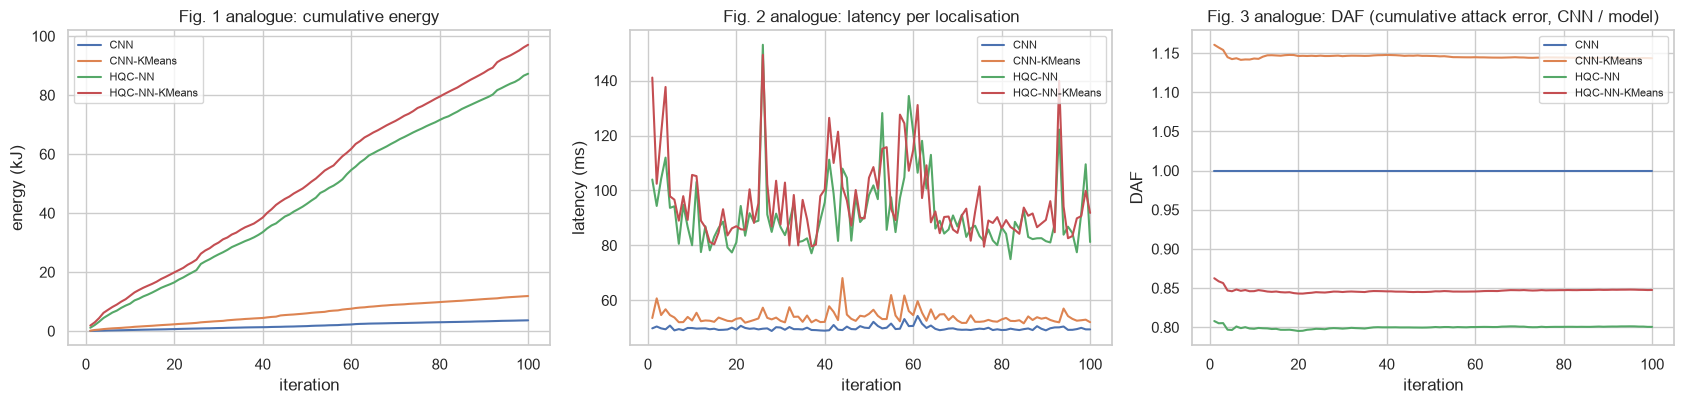

,energy at last iteration (kJ),mean latency (ms),single-sample compute (ms),DAF at last iteration,latency <= T_MAX,update rate >= R_MIN
CNN,3.639,49.847,1.335,1.000,True,True
CNN-KMeans,11.877,53.966,5.454,1.143,True,True
HQC-NN,87.251,91.653,43.141,0.800,False,False
HQC-NN-KMeans,97.069,96.561,48.049,0.848,False,False


In [22]:
# ---- the paper's Figs. 1-3: 100 iterations (mobility steps) of 1000 nodes, energy / latency / DAF per model ----
T_COMM = N_ANCH * PKT_BYTES * 8 / RATE_BPS                      # Eq. (4): N packets of 127 bytes at 250 kbit/s, one after the other
T_VERIFY = N_ANCH * C_CYCLES / F_CPU                            # Eq. (18)
E_VERIFY_J = P_CPU * T_VERIFY                                   # Eq. (19)
print(f"T_comm = {1e3 * T_COMM:.1f} ms, T_verify = {1e3 * T_VERIFY:.1f} ms per localisation (identical for all four models)")

M, K = TE["n_nodes"], TE["n_steps"]
mod0 = MODELS[SEEDS[0]]
ERR = {n: {c: errs(predict(mod, TE[k]), TE["pos"]).reshape(M, K) for c, k in [("clean", "m_clean"), ("NIFS", "m_nifs")]} for n, mod in mod0.items()}

def t_single(model, row):
    x = to_t(row[None]); t0 = time.perf_counter()
    with torch.no_grad(): model(x)
    return time.perf_counter() - t0
tg = np.random.default_rng(SEED + 5)
T_COMP = {n: np.zeros(K) for n in MODEL_NAMES}
for n, mod in mod0.items(): t_single(mod, TE["m_nifs"][0])                    # warm-up
for k in range(K):
    nodes = tg.choice(M, N_TIMING, replace=False)
    for n, mod in mod0.items():
        T_COMP[n][k] = np.mean([t_single(mod, TE["m_nifs"][nd * K + k]) for nd in nodes])
LAT = {n: 1e3 * (T_COMM + T_VERIFY + T_COMP[n]) for n in MODEL_NAMES}      # ms, Eq. (4)
ENERGY = {n: np.cumsum(M * (P_TX * T_COMM + E_VERIFY_J + P_EDGE * T_COMP[n])) / 1e3 for n in MODEL_NAMES}   # kJ, cumulative, Eq. (5)
CUM_ERR = {n: np.cumsum(ERR[n]["NIFS"].mean(0)) / np.arange(1, K + 1) for n in MODEL_NAMES}
DAF_K = {n: CUM_ERR["CNN"] / CUM_ERR[n] for n in MODEL_NAMES}
style = {"CNN": "C0", "CNN-KMeans": "C1", "HQC-NN": "C2", "HQC-NN-KMeans": "C3"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); it = np.arange(1, K + 1)
for n in MODEL_NAMES:
    ax[0].plot(it, ENERGY[n], color=style[n], label=n); ax[1].plot(it, LAT[n], color=style[n], label=n); ax[2].plot(it, DAF_K[n], color=style[n], label=n)
ax[0].set_title("Fig. 1 analogue: cumulative energy"); ax[0].set_ylabel("energy (kJ)")
ax[1].set_title("Fig. 2 analogue: latency per localisation"); ax[1].set_ylabel("latency (ms)")
ax[2].set_title("Fig. 3 analogue: DAF (cumulative attack error, CNN / model)"); ax[2].set_ylabel("DAF")
for a in ax: a.set_xlabel("iteration"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
final = pd.DataFrame({"energy at last iteration (kJ)": {n: ENERGY[n][-1] for n in MODEL_NAMES}, "mean latency (ms)": {n: LAT[n].mean() for n in MODEL_NAMES},
                      "single-sample compute (ms)": {n: 1e3 * T_COMP[n].mean() for n in MODEL_NAMES}, "DAF at last iteration": {n: DAF_K[n][-1] for n in MODEL_NAMES},
                      "latency <= T_MAX": {n: bool((LAT[n] / 1e3 <= T_MAX).all()) for n in MODEL_NAMES},
                      "update rate >= R_MIN": {n: bool((1e3 / LAT[n] >= R_MIN).all()) for n in MODEL_NAMES}}).round(3)
display(final)

## 9. Extension: worst-case (gradient) NIFS attack

The paper says its adversary is "worst-case", "additive but otherwise unconstrained" but only simulates random delays. Here the attacker is made concrete and is **white-box**: it owns two anchors, can only *delay* (delta >= 0), at most 40 ns (12 m), and picks the delays that maximise the squared position error of the attacked model by one FGSM step or 10 PGD steps. The bar chart compares them with random delays of the same size. This part is not in the paper and is the standard robustness test of this repository's adversarial-robustness notebooks.

RMSE in metres, 1000 test samples, 2 compromised anchors, delay up to 40 ns = 12 m (seed 42 models, white-box):


,clean,random NIFS,FGSM NIFS,PGD NIFS
model,,,,
LS multilateration,1.09,4.02,5.68,7.21
CNN,0.96,2.23,3.06,3.74
CNN-KMeans,1.02,1.98,2.58,3.32
HQC-NN,1.43,2.74,3.63,4.72
HQC-NN-KMeans,1.33,2.59,3.39,4.57


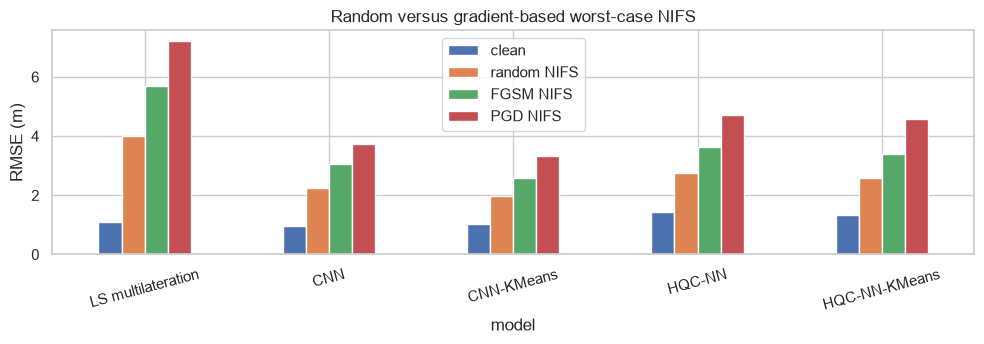

In [23]:
# ---- extension beyond the paper: the "worst-case adversarial model" of Sect. III-A made concrete as a white-box gradient attack ----
# The attacker owns PGD_NC anchors and may delay (never advance) their replies by up to PGD_EPS_NS: delta in [0, c*eps] on the compromised anchors.
def nifs_attack(model, m, pos, mode, seed, eps_m=C_LIGHT * PGD_EPS_NS * 1e-9, nc=PGD_NC, steps=PGD_STEPS):
    g = np.random.default_rng(seed); n = len(m)
    mask = np.zeros((n, N_ANCH), np.float32)
    for r in range(n): mask[r, g.choice(N_ANCH, nc, replace=False)] = 1
    mask_t = torch.tensor(mask); m_t = torch.tensor(m, dtype=torch.float32); y = torch.tensor(pos / AREA, dtype=torch.float32)
    if mode == "random":
        delta = mask_t * torch.tensor(g.uniform(0, eps_m, (n, N_ANCH)), dtype=torch.float32)
    else:
        delta = torch.zeros_like(m_t) if mode == "FGSM" else mask_t * torch.tensor(g.uniform(0, eps_m, (n, N_ANCH)), dtype=torch.float32)
        alpha = eps_m if mode == "FGSM" else 2.5 * eps_m / steps
        for _ in range(1 if mode == "FGSM" else steps):
            delta.requires_grad_(True)
            loss = ((model(((m_t + delta) / AREA)) - y) ** 2).sum()
            grad, = torch.autograd.grad(loss, delta)
            delta = ((delta.detach() + alpha * grad.sign() * mask_t).clamp(0.0, eps_m)) * mask_t
    return (m_t + delta).detach().numpy()

sel = np.random.default_rng(SEED + 9).choice(len(TE["pos"]), N_PGD, replace=False)
gm = {"LS multilateration": ls_model, **MODELS[SEEDS[0]]}
rows = []
for n, mod in gm.items():
    row = {"model": n, "clean": summarize(predict(mod, TE["m_clean"][sel]), TE["pos"][sel])["RMSE"]}
    for mode in ["random", "FGSM", "PGD"]:
        m_adv = nifs_attack(mod, TE["m_clean"][sel], TE["pos"][sel], mode, SEED)
        row[f"{mode} NIFS"] = summarize(predict(mod, m_adv), TE["pos"][sel])["RMSE"]
    rows.append(row)
PG = pd.DataFrame(rows).set_index("model").round(2)
print(f"RMSE in metres, {N_PGD} test samples, {PGD_NC} compromised anchors, delay up to {PGD_EPS_NS} ns = {C_LIGHT * PGD_EPS_NS * 1e-9:.0f} m (seed {SEEDS[0]} models, white-box):")
display(PG)
PG.plot.bar(figsize=(10, 3.6), rot=15, ylabel="RMSE (m)", title="Random versus gradient-based worst-case NIFS"); plt.tight_layout(); plt.show()

## 10. Side-by-side with the paper

Verdict rules: **reproduced** = same ordering, or a number within the stated tolerance (DAF: 0.15); **not reached** / **exceeded** = outside the tolerance, with the gap; **cannot be checked** = the paper's number depends on constants it does not report. All paper numbers are read off plots, so they are accurate to a few percent at best.

In [24]:
# ---- side-by-side with the paper (all paper numbers are read off Figs. 1-3, so they are +/- a few percent) ----
PAPER = {"energy": {"CNN": 38, "CNN-KMeans": 18, "HQC-NN": 43, "HQC-NN-KMeans": 21},
         "latency": {"CNN": 20, "CNN-KMeans": 18, "HQC-NN": 20, "HQC-NN-KMeans": 17},
         "daf": {"CNN": 1.0, "CNN-KMeans": 1.3, "HQC-NN": 1.25, "HQC-NN-KMeans": 1.6}}
nb_energy = {n: ENERGY[n][-1] for n in MODEL_NAMES}; nb_lat = {n: LAT[n].mean() for n in MODEL_NAMES}
nb_daf = {n: float(DAF[n].mean()) for n in MODEL_NAMES}
def order(d, rev=False): return (" > " if rev else " < ").join(sorted(d, key=d.get, reverse=rev))
rmse = lambda n, c: np.mean([RESULTS[s][n][c]["RMSE"] for s in SEEDS])
rows = []
for n in MODEL_NAMES:
    rows.append([f"DAF {n}", PAPER["daf"][n], round(nb_daf[n], 2), "reproduced" if abs(nb_daf[n] - PAPER["daf"][n]) <= 0.15 else
                 ("exceeded" if nb_daf[n] > PAPER["daf"][n] else "not reached") + f" (gap {nb_daf[n] - PAPER['daf'][n]:+.2f}; tolerance 0.15)"])
rows.append(["DAF ordering (best to worst)", order(PAPER["daf"], True), order(nb_daf, True), "reproduced" if order(PAPER["daf"], True) == order(nb_daf, True) else "not reached"])
for n in MODEL_NAMES:
    rows.append([f"Energy {n} (kJ after {K} iterations; paper: 100)", PAPER["energy"][n], round(nb_energy[n], 1), "cannot be checked: absolute value depends on unreported power constants"])
rows.append(["Energy ordering (low to high)", order(PAPER["energy"]), order(nb_energy), "reproduced" if order(PAPER["energy"]) == order(nb_energy) else "not reached"])
for n in MODEL_NAMES:
    rows.append([f"Latency {n} (ms)", PAPER["latency"][n], round(nb_lat[n], 1), "cannot be checked: absolute value depends on unreported link / CPU constants"])
rows.append(["Latency ordering (low to high)", order(PAPER["latency"]), order(nb_lat), "reproduced" if order(PAPER["latency"]) == order(nb_lat) else "not reached"])
rows.append(["Claim: HQC-NN more accurate than CNN under NIFS", "yes (conclusion)", f"{rmse('HQC-NN', 'NIFS'):.2f} m vs {rmse('CNN', 'NIFS'):.2f} m",
             "reproduced" if rmse("HQC-NN", "NIFS") < rmse("CNN", "NIFS") else "not reached"])
rows.append(["Claim: HQC-NN-KMeans more accurate than CNN under NIFS", "yes (conclusion)", f"{rmse('HQC-NN-KMeans', 'NIFS'):.2f} m vs {rmse('CNN', 'NIFS'):.2f} m",
             "reproduced" if rmse("HQC-NN-KMeans", "NIFS") < rmse("CNN", "NIFS") else "not reached"])
rows.append(["Claim: K-Means helps (CNN-KMeans vs CNN, HQC-NN-KMeans vs HQC-NN), NIFS RMSE", "yes", f"{rmse('CNN-KMeans', 'NIFS'):.2f} vs {rmse('CNN', 'NIFS'):.2f} m; {rmse('HQC-NN-KMeans', 'NIFS'):.2f} vs {rmse('HQC-NN', 'NIFS'):.2f} m",
             "reproduced" if rmse("CNN-KMeans", "NIFS") < rmse("CNN", "NIFS") and rmse("HQC-NN-KMeans", "NIFS") < rmse("HQC-NN", "NIFS") else "not reached"])
rows.append(["Claim: Ed25519 signatures stop spoofing (impersonation) but a NIFS node with a valid key passes", "implied (Sect. I, IV-A)",
             f"B: {sec.iloc[0 + 2]['packets with valid signature']} / C: {sec.iloc[4]['packets with valid signature']} valid packets", "reproduced" if sec.iloc[4]["packets with valid signature"].startswith("100") else "not reached"])
rows.append(["Claim: quantum-enhanced and cluster-specialised models are more energy efficient than the CNN", "yes (Sect. V-A)", order(nb_energy),
             "reproduced" if nb_energy["HQC-NN-KMeans"] < nb_energy["CNN"] else "not reached"])
CMP = pd.DataFrame(rows, columns=["claim / quantity", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 220)
display(CMP)
print(f"total notebook run time: {(time.time() - T_NOTEBOOK) / 60:.1f} min (FAST_MODE={FAST_MODE})")

,claim / quantity,paper,this notebook,verdict
0,DAF CNN,1.0,1.0,reproduced
1,DAF CNN-KMeans,1.3,1.1,not reached (gap -0.20; tolerance 0.15)
2,DAF HQC-NN,1.25,0.7,not reached (gap -0.55; tolerance 0.15)
3,DAF HQC-NN-KMeans,1.6,0.75,not reached (gap -0.85; tolerance 0.15)
4,DAF ordering (best to worst),HQC-NN-KMeans > CNN-KMeans > HQC-NN > CNN,CNN-KMeans > CNN > HQC-NN-KMeans > HQC-NN,not reached
5,Energy CNN (kJ after 100 iterations; paper: 100),38,3.6,cannot be checked: absolute value depends on unreported power constants
6,Energy CNN-KMeans (kJ after 100 iterations; paper: 100),18,11.9,cannot be checked: absolute value depends on unreported power constants
7,Energy HQC-NN (kJ after 100 iterations; paper: 100),43,87.3,cannot be checked: absolute value depends on unreported power constants
8,Energy HQC-NN-KMeans (kJ after 100 iterations; paper: 100),21,97.1,cannot be checked: absolute value depends on unreported power constants
9,Energy ordering (low to high),CNN-KMeans < HQC-NN-KMeans < CNN < HQC-NN,CNN < CNN-KMeans < HQC-NN < HQC-NN-KMeans,not reached


total notebook run time: 71.8 min (FAST_MODE=False)


## Reading the paper critically

- **No reproducible protocol.** The paper reports no anchor count, area, noise level, attack strength, `K`, qubit count, ansatz, training budget, error in metres or definition of DAF. All three results are line plots without numbers. Whether the paper's claims hold depends on exactly those choices; this notebook shows what happens for one documented set of choices.
- **The central claim is about security, but the security is mostly outside the model.** Ed25519 stops forged packets (scenario B) and does nothing against NIFS (scenario C), because NIFS nodes sign their delayed answers themselves. The only NIFS defence is the robustness of the estimator, and the paper never reports a localisation error in metres under attack, only energy, latency and the undefined DAF.
- **DAF is relative.** A curve that equals 1 for the baseline and reaches 1.6 for the proposal says "1.6 times better at something". Better at what (error, detection rate, a mixture) matters: our attack-error ratio and our detector AUC rank the models differently.
- **The classical baselines are weak or absent.** Least-squares multilateration, a Random Forest and an SVR cost almost nothing; the table in Section 5 shows how they compare with the CNN family, and whether the quantum layer adds anything over the CNN alone.
- **Quantum energy is assumed, not measured.** On a classical simulator the circuit is much slower than a CNN of the same output size. The paper's lower energy for the quantum model rests on offloading to an unspecified edge server with unspecified power. The paper's energy figure also puts HQC-NN (43 kJ) above the CNN (38 kJ) while the text says the quantum models are "energy efficient".
- **K-Means helps by construction in the paper's figures** (18 kJ and 17 ms for the clustered versions) but not necessarily in practice: clustering distance vectors that already carry the attack can send an attacked sample to the wrong region, and a branch is no cheaper than the global network unless it is smaller.
- **Simulation only.** No real RSSI/CSI or ranging data, no hardware, no actual quantum device; the claims are as realistic as the simulator, which is not published.

## Exercises

1. **Anchor count and geometry.** Change `N_ANCH` (and the anchor list) to 4, 6 and 12 and rerun. How many compromised anchors can each model tolerate before the RMSE explodes? Why does least squares break down first?
2. **Stronger or weaker attack.** Sweep the NIFS delay range `DT_NS_TRAIN` from 2 ns to 100 ns. At which delay does the residual detector of Section 6 reach AUC 0.9?
3. **Circuit variants.** Replace `StronglyEntanglingLayers` by no entanglement at all (rotations only) or by 1 and 4 layers. Does the HQC-NN error change? Which part of the benefit, if any, comes from entanglement?
4. **A fairer energy model.** Replace the edge-server power by a different value or give the quantum part a fixed 1 ms latency (quantum offloading). At which constants does the paper's ordering of Fig. 1 appear? What does that say about the claim?
5. **Defence by training.** Train the CNN with the PGD attack of Section 9 inside the loop (adversarial training) and compare with the models trained on random NIFS only. Does the gap between CNN and HQC-NN change?